# Fase 4b/5 — CNN desde cero y comparación con ML clásico

La CNN se entrena con `scripts/train_cnn.py`; este notebook **lee los resultados guardados** (historias, predicciones y pesos) y los analiza.

- **Entrada:** recorte 128×128 de la fruta principal con el fondo en negro (`scripts/cache_tiles.py`).
- **Arquitectura:** 3 bloques [Conv3×3 → BN → ReLU]×2 → MaxPool, con 16/32/64 filtros, Global Average Pooling, Dropout y capa densa. ~72 mil parámetros (ver `src/fruitq/cnn.py`).
- **Entrenamiento:** AdamW, decaimiento coseno, entropía cruzada $\mathcal L = -\frac1N\sum_i \log \mathrm{softmax}(z_i)_{y_i}$, muestreo balanceado por estrato, aumento con las 8 simetrías del cuadrado y brillo/contraste, parada temprana con el F1 de validación.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, torch
from sklearn.metrics import f1_score, accuracy_score, recall_score, roc_auc_score, classification_report, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from scipy.stats import binomtest
from fruitq.config import PROCESSED, FIGURES, MODELS, SEED
from fruitq.cnn import SmallCNN, MEAN, STD, TILE

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
CNN = ROOT / "reports" / "cnn"
def savefig(name):
    plt.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight"); plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Búsqueda de hiperparámetros

In [2]:
res = pd.DataFrame([json.loads(p.read_text()) for p in sorted(CNN.glob("*_resumen.json"))])
res["lr"] = res.args.map(lambda a: a["lr"]); res["dropout"] = res.args.map(lambda a: a["dropout"])
tabla = res[["tag", "lr", "dropout", "params", "mejor_epoca", "epocas", "f1_val", "min_total"]].sort_values("f1_val", ascending=False)
tabla.round(4)

,tag,lr,dropout,params,mejor_epoca,epocas,f1_val,min_total
1,lr1e-3_do0.5,0.0010,0.5,72434,17,20,0.9345,34.4273
0,lr1e-3_do0.3,0.0010,0.3,72434,18,20,0.9315,35.0391
2,lr3e-4_do0.3,0.0003,0.3,72434,17,20,0.9236,35.1154


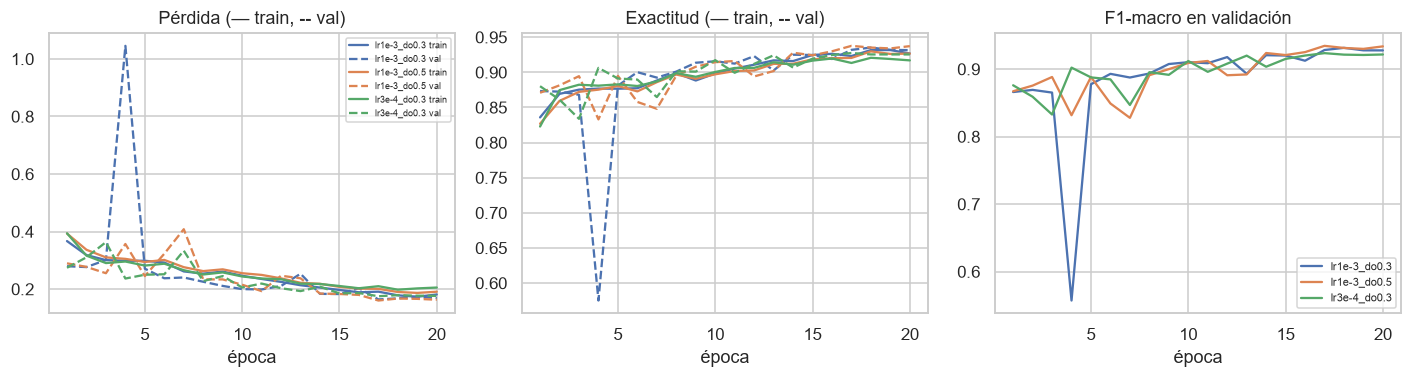

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for tag in res.tag:
    h = pd.read_csv(CNN / f"{tag}_historia.csv")
    l, = axes[0].plot(h.epoca, h.loss_train, label=f"{tag} train")
    axes[0].plot(h.epoca, h.loss_val, "--", color=l.get_color(), label=f"{tag} val")
    axes[1].plot(h.epoca, h.acc_train, color=l.get_color()); axes[1].plot(h.epoca, h.acc_val, "--", color=l.get_color())
    axes[2].plot(h.epoca, h.f1_val, color=l.get_color(), label=tag)
axes[0].set_title("Pérdida (— train, -- val)"); axes[1].set_title("Exactitud (— train, -- val)"); axes[2].set_title("F1-macro en validación")
for a in axes: a.set_xlabel("época")
axes[0].legend(fontsize=6); axes[2].legend(fontsize=7)
plt.tight_layout(); savefig("cnn_curvas"); plt.show()

**Cómo leer las curvas.** Si la pérdida de validación sube mientras la de entrenamiento sigue bajando, hay **sobreajuste**, y la parada temprana guarda la época anterior a ese punto. Aquí la exactitud de train se mide *con aumento de datos*, una tarea más difícil que validación, así que puede quedar por debajo de val sin que eso sea un error.

## 2. Mejor CNN en test vs. XGBoost

In [4]:
best_tag = tabla.iloc[0].tag
pc = pd.read_csv(CNN / f"{best_tag}_predicciones.csv")
pc_te = pc[pc.split == "test"].reset_index(drop=True)

feats = pd.read_parquet(PROCESSED / "features.parquet")
xgb = joblib.load(MODELS / "clasico_mejor.joblib")
te = feats[feats.split == "test"].set_index("path").loc[pc_te.path]
pc_te["p_xgb"] = xgb["modelo"].predict_proba(te[xgb["features"]].values)[:, 1]
pc_te["p_ens"] = (pc_te.p_mala + pc_te.p_xgb) / 2   # ensamble: promedio de probabilidades

y = pc_te.y.values
filas = []
for nombre, col in ((f"CNN ({best_tag})", "p_mala"), (f"XGBoost", "p_xgb"), ("Ensamble CNN+XGB", "p_ens")):
    p = pc_te[col].values; yhat = (p >= 0.5).astype(int)
    filas.append({"modelo": nombre, "accuracy": accuracy_score(y, yhat), "F1-macro": f1_score(y, yhat, average="macro"),
                  "recall(mala)": recall_score(y, yhat), "AUC": roc_auc_score(y, p)})
comp = pd.DataFrame(filas).set_index("modelo").round(4)
comp.to_csv(FIGURES.parent / "tabla_cnn_vs_xgb_test.csv")
comp

,accuracy,F1-macro,recall(mala),AUC
modelo,,,,
CNN (lr1e-3_do0.5),0.9413,0.9397,0.9389,0.9832
XGBoost,0.9654,0.9642,0.9504,0.9901
Ensamble CNN+XGB,0.9638,0.9626,0.9552,0.9911


### ¿La diferencia es significativa? Prueba de McNemar

Ambos modelos se evalúan sobre **las mismas** imágenes, así que se comparan sus desacuerdos: $b$ = imágenes que solo acierta la CNN y $c$ = imágenes que solo acierta XGBoost. Bajo $H_0$ (los dos son igual de buenos), cada desacuerdo cae de un lado o del otro con probabilidad ½, es decir $b \sim \mathrm{Bin}(b+c,\ \tfrac12)$. Un valor $p < 0.05$ indica que la diferencia no se explica por azar.

In [5]:
ok_cnn = (pc_te.p_mala >= 0.5).astype(int) == y
ok_xgb = (pc_te.p_xgb >= 0.5).astype(int) == y
b, c = int((ok_cnn & ~ok_xgb).sum()), int((~ok_cnn & ok_xgb).sum())
p = binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
print(f"Solo acierta la CNN: b = {b} | solo acierta XGBoost: c = {c} | McNemar exacto p = {p:.4f}")
print(f"Ambos fallan: {int((~ok_cnn & ~ok_xgb).sum())} imágenes (errores 'duros', posible ruido de etiqueta)")

Solo acierta la CNN: b = 31 | solo acierta XGBoost: c = 92 | McNemar exacto p = 0.0000
Ambos fallan: 57 imágenes (errores 'duros', posible ruido de etiqueta)


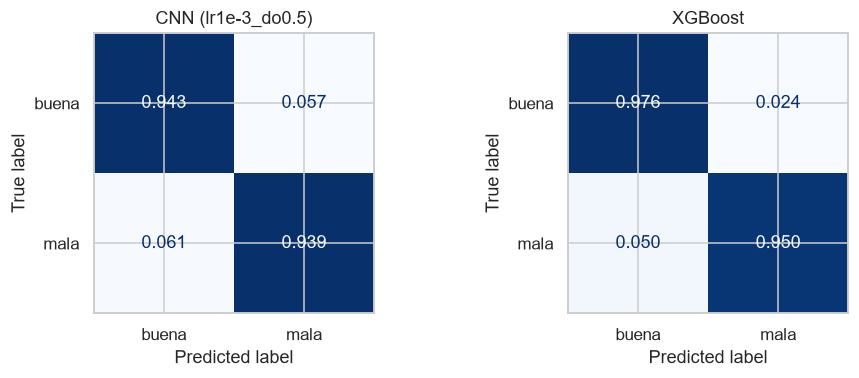

ok_cnn  ok_xgb
fruta   calidad                
banano  buena     0.969   1.000
        mala      0.852   0.923
granada buena     0.984   0.996
        mala      0.970   0.959
guayaba buena     0.963   0.988
        mala      0.938   0.975
limon   buena     0.994   1.000
        mala      0.974   0.981
manzana buena     0.835   0.896
        mala      0.920   0.951
naranja buena     0.798   0.919
        mala      0.963   0.927

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, col, t in ((axes[0], "p_mala", f"CNN ({best_tag})"), (axes[1], "p_xgb", "XGBoost")):
    ConfusionMatrixDisplay.from_predictions(y, (pc_te[col] >= 0.5).astype(int), display_labels=["buena", "mala"],
                                            normalize="true", values_format=".3f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(t)
plt.tight_layout(); savefig("cnn_vs_xgb_confusion"); plt.show()

pc_te["ok_cnn"], pc_te["ok_xgb"] = ok_cnn, ok_xgb
pc_te.groupby(["fruta", "calidad"])[["ok_cnn", "ok_xgb"]].mean().round(3)

## 3. Calibración: ¿las probabilidades sirven para la clase `regular`?

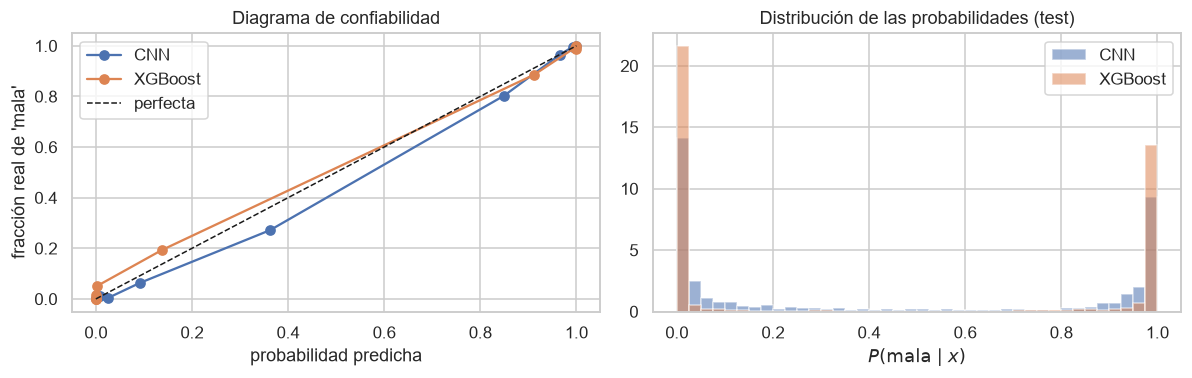

CNN: 10.9% de las imágenes con probabilidad intermedia (0.2–0.8)
XGBoost: 4.4% de las imágenes con probabilidad intermedia (0.2–0.8)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for col, nombre in (("p_mala", "CNN"), ("p_xgb", "XGBoost")):
    fr, mp = calibration_curve(y, pc_te[col], n_bins=10, strategy="quantile")
    axes[0].plot(mp, fr, "o-", label=nombre)
    axes[1].hist(pc_te[col], bins=40, alpha=0.55, label=nombre, density=True)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfecta")
axes[0].set_xlabel("probabilidad predicha"); axes[0].set_ylabel("fracción real de 'mala'"); axes[0].set_title("Diagrama de confiabilidad"); axes[0].legend()
axes[1].set_xlabel(r"$P(\mathrm{mala}\mid x)$"); axes[1].set_title("Distribución de las probabilidades (test)"); axes[1].legend()
plt.tight_layout(); savefig("cnn_calibracion"); plt.show()
for col, nombre in (("p_mala", "CNN"), ("p_xgb", "XGBoost")):
    print(f"{nombre}: {((pc_te[col] > 0.2) & (pc_te[col] < 0.8)).mean():.1%} de las imágenes con probabilidad intermedia (0.2–0.8)")

## 4. ¿Dónde mira la red? Grad-CAM

Grad-CAM (Selvaraju et al., 2017) pondera los mapas de activación $A^k$ del último bloque convolucional por la importancia de cada canal, $\alpha_k = \frac{1}{HW}\sum_{i,j} \partial z_{\text{mala}} / \partial A^k_{ij}$, y calcula $\mathrm{ReLU}\left(\sum_k \alpha_k A^k\right)$. Las zonas cálidas son las que más empujan la predicción hacia `mala`. Si la red funciona bien, deberían coincidir con las manchas o la podredumbre.

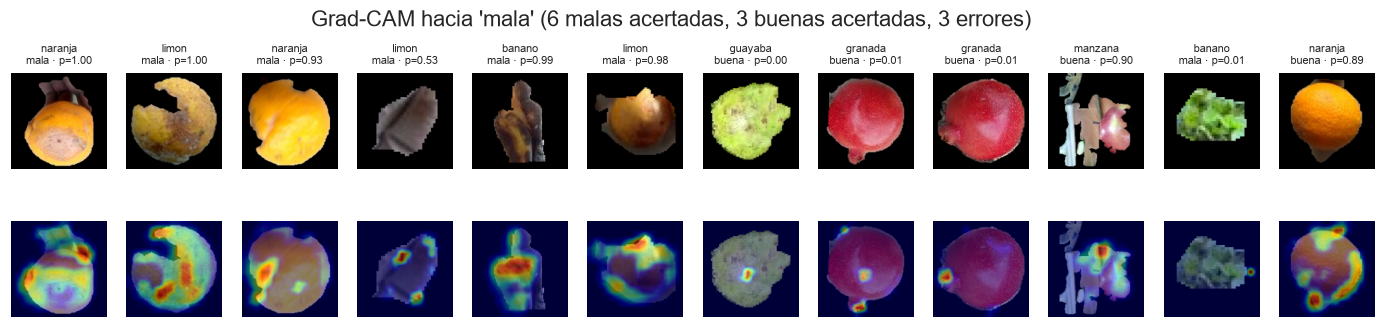

In [8]:
ck = torch.load(MODELS / f"cnn_{best_tag}.pt")
net = SmallCNN(2, tuple(ck["widths"]), ck["dropout"]); net.load_state_dict(ck["state_dict"]); net.eval()
tiles = np.load(PROCESSED / f"tiles{TILE}.npy", mmap_mode="r")
m = pd.read_csv(PROCESSED / "manifest.csv"); pos = pd.Series(m.index, index=m.path)

acts = {}
h = net.features[-1].register_forward_hook(lambda mod, i, o: acts.__setitem__("a", o))
def gradcam(tile):
    x = torch.from_numpy(((tile.astype(np.float32) / 255 - MEAN) / STD)).permute(2, 0, 1)[None].requires_grad_(True)
    z = net(x); acts["a"].retain_grad(); z[0, 1].backward()
    a, g = acts["a"][0], acts["a"].grad[0]
    cam = torch.relu((g.mean((1, 2))[:, None, None] * a).sum(0)).detach().numpy()
    cam = cam / (cam.max() + 1e-8)
    import cv2
    return cv2.resize(cam, (TILE, TILE)), torch.softmax(z, 1)[0, 1].item()

sel = pd.concat([pc_te[(pc_te.y == 1) & ok_cnn].sample(6, random_state=SEED), pc_te[(pc_te.y == 0) & ok_cnn].sample(3, random_state=SEED),
                 pc_te[~ok_cnn].sample(3, random_state=SEED)])
fig, axes = plt.subplots(2, 12, figsize=(16, 3.2))
for j, r in enumerate(sel.itertuples()):
    t = np.asarray(tiles[pos[r.path]]); cam, pm = gradcam(t)
    axes[0, j].imshow(t); axes[0, j].set_title(f"{r.fruta}\n{r.calidad} · p={pm:.2f}", fontsize=7)
    axes[1, j].imshow(t); axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
for a in axes.ravel(): a.axis("off")
plt.suptitle("Grad-CAM hacia 'mala' (6 malas acertadas, 3 buenas acertadas, 3 errores)", y=1.02); savefig("cnn_gradcam"); plt.show()
h.remove()